# Semantic segmentation evaluation

In [121]:

import warnings
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForSemanticSegmentation,
    Mask2FormerForUniversalSegmentation,
    MobileViTForSemanticSegmentation,
    SegformerForSemanticSegmentation,
)

warnings.filterwarnings("ignore")
plt.style.use("ggplot")

device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [122]:
from pathlib import Path
from io import BytesIO

import pandas as pd
import numpy as np
from PIL import Image

parquet_dir = Path("~/.cache/huggingface/lerobot/libero/data/chunk-000").expanduser()

parquet_files = sorted(parquet_dir.glob("*.parquet"))
assert parquet_files, f"No parquet files found in {parquet_dir}"
parquet_file = parquet_files[0]
print("Using parquet file:", parquet_file)

df = pd.read_parquet(parquet_file)
print("Columns:", df.columns)

frame_idx = 800



print(f"Using frame_idx = {frame_idx} (total frames: {len(df)})")

row = df.iloc[frame_idx]
entry = row["observation.images.image"]  


if isinstance(entry, Image.Image):
    image = entry.convert("RGB")

elif isinstance(entry, dict):
    
    if "bytes" in entry and entry["bytes"] is not None:
        image = Image.open(BytesIO(entry["bytes"])).convert("RGB")
    elif "path" in entry and entry["path"] is not None:
        image = Image.open(entry["path"]).convert("RGB")
    else:
        raise ValueError("Image dict has neither 'bytes' nor 'path'.")

elif isinstance(entry, (bytes, bytearray)):
    image = Image.open(BytesIO(entry)).convert("RGB")

elif isinstance(entry, np.ndarray):
    image = Image.fromarray(entry).convert("RGB")

else:
    raise TypeError(f"Don't know how to turn {type(entry)} into an image, got {type(entry)}")

print("Loaded image size:", image.size)

Using parquet file: /Users/riteshsingh/.cache/huggingface/lerobot/libero/data/chunk-000/file-000.parquet
Columns: Index(['observation.images.image', 'observation.images.image2',
       'observation.state', 'action', 'timestamp', 'frame_index',
       'episode_index', 'index', 'task_index'],
      dtype='object')
Using frame_idx = 800 (total frames: 843)
Loaded image size: (256, 256)


In [123]:




def load_model(ckpt: str) -> tuple[AutoImageProcessor, torch.nn.Module]:
    processor = AutoImageProcessor.from_pretrained(ckpt)

    model: torch.nn.Module
    if "mask2former" in ckpt:
        model = Mask2FormerForUniversalSegmentation.from_pretrained(ckpt)
    elif "segformer" in ckpt:
        model = SegformerForSemanticSegmentation.from_pretrained(ckpt)
    elif "deeplab" in ckpt or "mobilevit" in ckpt:
        model = MobileViTForSemanticSegmentation.from_pretrained(ckpt)
    else:
        model = AutoModelForSemanticSegmentation.from_pretrained(ckpt)

    model = model.to(device)
    model = model.eval()
    return processor, model


@torch.no_grad()
def get_segmentation(processor, model, pil_image: Image.Image):
    inputs = processor(images=pil_image, return_tensors="pt").to(device)
    outputs = model(**inputs)
    target_sizes = [pil_image.size[::-1]]  # (H, W)

    seg = None

    if hasattr(processor, "post_process_semantic_segmentation"):
        processed = processor.post_process_semantic_segmentation(
            outputs=outputs,
            target_sizes=target_sizes,
        )

        seg0 = processed[0]


        if isinstance(seg0, dict):
            seg = seg0["segmentation"]
        else:

            seg = seg0


    if seg is None:
        logits = outputs.logits  
        seg = torch.nn.functional.interpolate(
            logits,
            size=target_sizes[0],
            mode="bilinear",
            align_corners=False,
        ).argmax(dim=1)[0]  


    if isinstance(seg, torch.Tensor):
        seg = seg.detach().cpu().numpy()

    return seg.astype(np.int64)


def build_palette(num_colors: int = 256, seed: int = 0):
    rng = np.random.default_rng(seed)
    colors = rng.integers(0, 255, size=(num_colors, 3), dtype=np.uint8)
    colors[0] = np.array([0, 0, 0], dtype=np.uint8)
    return colors


PALETTE = build_palette()


def to_overlay(pil_image: Image.Image, segmentation: np.ndarray):
    colored = PALETTE[segmentation % PALETTE.shape[0]]
    seg_img = Image.fromarray(colored)
    return Image.blend(pil_image.convert("RGBA"), seg_img.convert("RGBA"), alpha=0.5)


def describe_segmentation(
    segmentation: np.ndarray,
    id2label: dict,
    top_k: int = 5,
    force_substrings: list[str] | None = None,
):
    
    ids, counts = np.unique(segmentation, return_counts=True)
    total = segmentation.size
    order = counts.argsort()[::-1]

    counts_by_id = {int(label_id): int(ct) for label_id, ct in zip(ids, counts)}

    rows = []
    seen_ids: set[int] = set()
    for idx in order[:top_k]:
        label_id = int(ids[idx])
        seen_ids.add(label_id)
        rows.append(
            {
                "label_id": label_id,
                "label": id2label.get(label_id, f"class_{label_id}"),
                "pixels": int(counts[idx]),
                "share": float(counts[idx] / total),
            }
        )

    if force_substrings:
        needles = [s.lower() for s in force_substrings]
        for label_id in ids:
            lid = int(label_id)
            if lid in seen_ids:
                continue
            name = str(id2label.get(lid, f"class_{lid}"))
            lower = name.lower()
            if any(n in lower for n in needles):
                ct = counts_by_id.get(lid, 0)
                rows.append(
                    {
                        "label_id": lid,
                        "label": name,
                        "pixels": int(ct),
                        "share": float(ct / total) if total else 0.0,
                    }
                )
                seen_ids.add(lid)

    stats = {
        "num_pixels": int(total),
        "num_labels": len(ids),
        "entropy": float(-(counts / total * np.log((counts / total) + 1e-12)).sum()),
    }
    return pd.DataFrame(rows), stats


def mean_label_iou(seg_a: np.ndarray, seg_b: np.ndarray):
    labels = np.union1d(np.unique(seg_a), np.unique(seg_b))
    scores = []
    for label in labels:
        mask_a = seg_a == label
        mask_b = seg_b == label
        union = mask_a | mask_b
        if union.sum() == 0:
            continue
        intersection = (mask_a & mask_b).sum()
        scores.append(intersection / union.sum())
    return float(np.mean(scores)) if scores else float("nan")


def pixel_agreement(seg_a: np.ndarray, seg_b: np.ndarray):
    return float((seg_a == seg_b).mean())


Done -> facebook/mask2former-swin-large-ade-semantic on cpu | labels=7, entropy=1.295


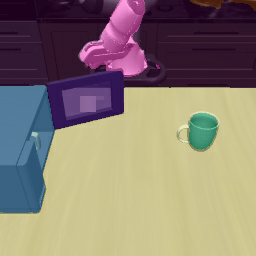

,label_id,label,pixels,share
0,3,floor,33846,0.516449
1,10,cabinet,17995,0.274582
2,15,table,6035,0.092087
3,141,crt screen,3430,0.052338
4,71,stove,3083,0.047043
5,147,glass,835,0.012741
6,47,sink,312,0.004761


Done -> nvidia/segformer-b2-finetuned-ade-512-512 on cpu | labels=16, entropy=1.193


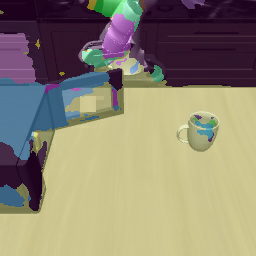

,label_id,label,pixels,share
0,3,floor,37761,0.576187
1,10,cabinet,18004,0.274719
2,15,table,5128,0.078247
3,33,desk,1454,0.022186
4,132,sculpture,1056,0.016113
5,75,swivel chair,913,0.013931
6,8,windowpane,407,0.006210
7,138,cup,174,0.002655
8,64,coffee table,170,0.002594
9,107,washer,139,0.002121


Done -> apple/deeplabv3-mobilevit-small on cpu | labels=1, entropy=-0.000


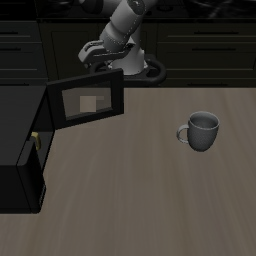

,label_id,label,pixels,share
0,0,background,65536,1.0


In [124]:


model_ids = [
    "facebook/mask2former-swin-large-ade-semantic",
    "nvidia/segformer-b2-finetuned-ade-512-512",
    "apple/deeplabv3-mobilevit-small",
]


CUP_SYNONYMS = ["cup", "mug", "glass", "goblet"]

DISPLAY_ALIAS = {
    "ashcan": "cup",
    "wastebasket": "cup",
}

def remap_label(name: str) -> str:
    key = str(name).lower()
    return DISPLAY_ALIAS.get(key, name)

results = {}
for ckpt in model_ids:
    processor, model = load_model(ckpt)
    segmentation = get_segmentation(processor, model, image)
    overlay = to_overlay(image, segmentation)


    id2label: dict[int, str]
    raw_id2label = getattr(model.config, "id2label", None)
    if isinstance(raw_id2label, dict):
        id2label = {int(k): str(v) for k, v in raw_id2label.items()}
    else:
        max_label = int(np.max(segmentation)) if segmentation.size else 0
        num_labels = int(getattr(model.config, "num_labels", max_label + 1))
        id2label = {i: f"class_{i}" for i in range(num_labels)}

    top_labels, stats = describe_segmentation(
        segmentation,
        id2label,
        top_k=10,  
        force_substrings=CUP_SYNONYMS,  
    )


    if "label" in top_labels.columns:
        top_labels["label"] = top_labels["label"].apply(remap_label)

    results[ckpt] = {
        "segmentation": segmentation,
        "overlay": overlay,
        "top_labels": top_labels,
        "stats": stats,
        "id2label": id2label,
    }
    print(f"Done -> {ckpt} on {device} | labels={stats['num_labels']}, entropy={stats['entropy']:.3f}")

    display(overlay)
    display(top_labels)

    del model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None


In [125]:
print("Results keys:", list(results.keys()))

Results keys: ['facebook/mask2former-swin-large-ade-semantic', 'nvidia/segformer-b2-finetuned-ade-512-512', 'apple/deeplabv3-mobilevit-small']


In [126]:

per_model_rows = []
for ckpt, res in results.items():
    dominant = res["top_labels"].iloc[0]
    per_model_rows.append(
        {
            "model": ckpt,
            "labels_predicted": res["stats"]["num_labels"],
            "dominant_label": dominant["label"],
            "dominant_share": dominant["share"],
            "entropy": res["stats"]["entropy"],
        }
    )

per_model_df = pd.DataFrame(per_model_rows)
per_model_df


,model,labels_predicted,dominant_label,dominant_share,entropy
0,facebook/mask2former-swin-large-ade-semantic,7,floor,0.516449,1.295026e+00
1,nvidia/segformer-b2-finetuned-ade-512-512,16,floor,0.576187,1.193031e+00
2,apple/deeplabv3-mobilevit-small,1,background,1.000000,-1.000089e-12


In [127]:

pairwise_rows = []

available_ids = list(results.keys())

for i, left_id in enumerate(available_ids):
    for right_id in available_ids[i + 1:]:
        seg_a = results[left_id]["segmentation"]
        seg_b = results[right_id]["segmentation"]

        pairwise_rows.append(
            {
                "model_a": left_id,
                "model_b": right_id,
                "pixel_agreement": pixel_agreement(seg_a, seg_b),
                "mean_label_iou": mean_label_iou(seg_a, seg_b),
            }
        )

pairwise_df = pd.DataFrame(pairwise_rows)
pairwise_df


,model_a,model_b,pixel_agreement,mean_label_iou
0,facebook/mask2former-swin-large-ade-semantic,nvidia/segformer-b2-finetuned-ade-512-512,0.79657,0.107161
1,facebook/mask2former-swin-large-ade-semantic,apple/deeplabv3-mobilevit-small,0.00000,0.000000
2,nvidia/segformer-b2-finetuned-ade-512-512,apple/deeplabv3-mobilevit-small,0.00000,0.000000


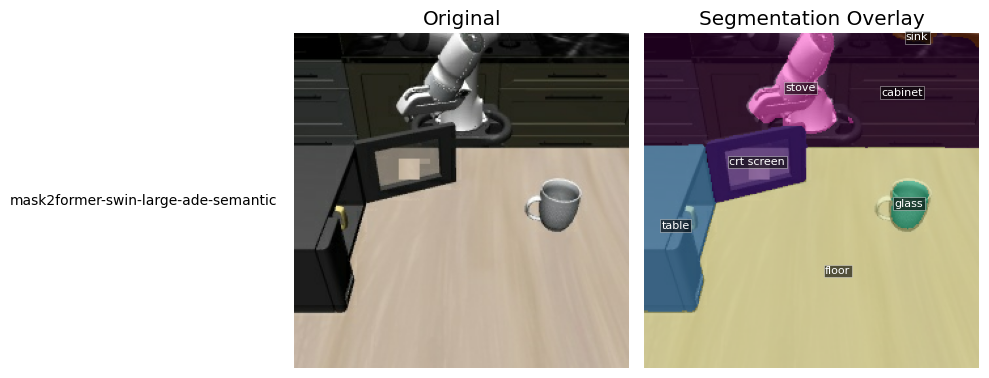

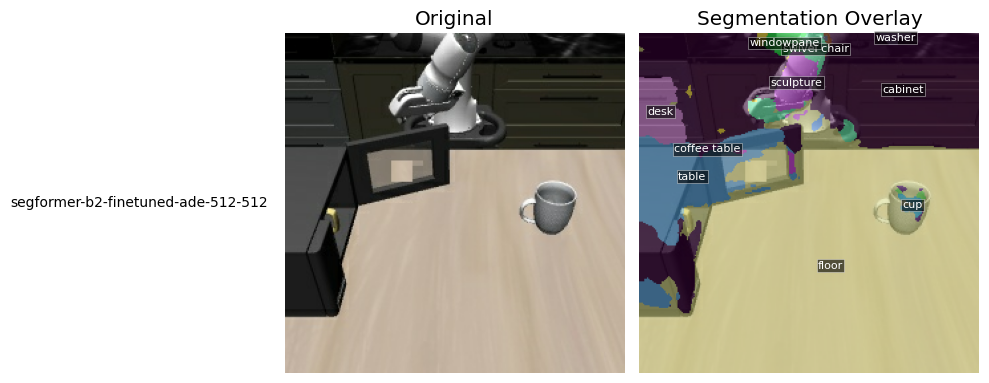

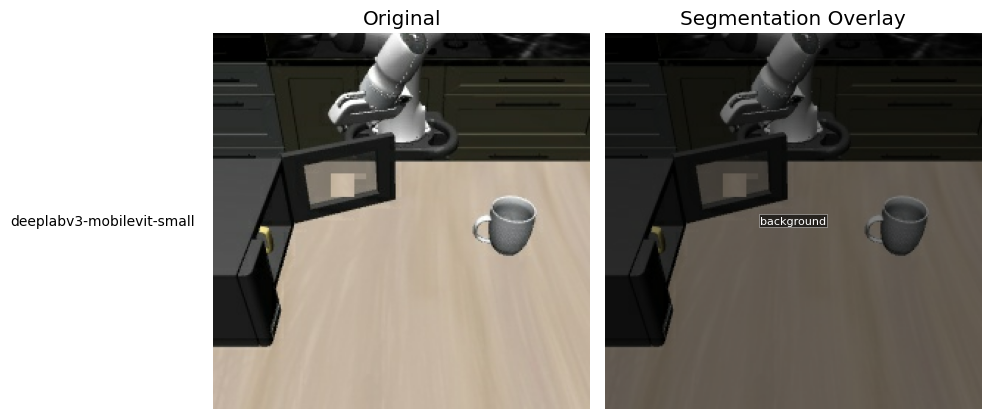

In [128]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage  


LABEL_ALIAS = {
    "ashcan": "cup",
    "wastebasket": "cup",
}

def display_name(name: str) -> str:
    key = str(name).lower()
    return LABEL_ALIAS.get(key, name)

for ckpt in model_ids:
    short_name = ckpt.split("/")[-1]
    seg: np.ndarray = np.asarray(results[ckpt]["segmentation"])      
    overlay: Image.Image = results[ckpt]["overlay"]       
    top_labels: pd.DataFrame = results[ckpt]["top_labels"] 
    id2label = results[ckpt].get("id2label", {})

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))


    ax_orig = axes[0]
    ax_orig.imshow(image)
    ax_orig.set_title("Original")
    ax_orig.axis("off")

    
    ax_orig.text(
        -0.05, 0.5,
        short_name,
        transform=ax_orig.transAxes,
        ha="right",
        va="center",
        fontsize=10,
    )

    
    ax_seg = axes[1]
    ax_seg.imshow(overlay)
    ax_seg.set_title("Segmentation Overlay")
    ax_seg.axis("off")


    for _, row_lbl in top_labels.iterrows():
        label_id = int(row_lbl["label_id"])
        label_name_raw = row_lbl.get("label") or id2label.get(label_id, f"class_{label_id}")
        label_name = display_name(label_name_raw)

        
        mask: np.ndarray = np.asarray(seg == label_id, dtype=bool)
        if not mask.any():
            continue


        labeled_cc: np.ndarray
        num_cc: int
        labeled_cc, num_cc = ndimage.label(mask)
        if num_cc == 0:
            continue

        
        sizes = np.asarray(ndimage.sum(mask, labeled_cc, index=range(1, num_cc + 1)))
        largest_id = int(np.argmax(sizes)) + 1

        ys, xs = np.where(labeled_cc == largest_id)
        if len(xs) == 0:
            continue

        y = ys.mean()
        x = xs.mean()

        ax_seg.text(
            x, y, label_name,
            ha="center",
            va="center",
            fontsize=8,
            color="white",
            bbox=dict(facecolor="black", alpha=0.6, pad=1),
        )

    plt.tight_layout()
    plt.show()


In [129]:

def consensus_segmentation(results: dict):
    """Majority-vote consensus from all model segmentations."""
    model_names = list(results.keys())
    segs = np.stack([results[m]["segmentation"] for m in model_names], axis=0)  # (K, H, W)
    K, H, W = segs.shape
    segs_flat = segs.reshape(K, -1)

    def majority_vote(col):
        vals, counts = np.unique(col, return_counts=True)
        return vals[counts.argmax()]

    consensus_flat = np.apply_along_axis(majority_vote, 0, segs_flat)
    return consensus_flat.reshape(H, W)

def confusion_from_masks(pred: np.ndarray, target: np.ndarray, num_classes: int | None = None):
    """Return confusion matrix of shape (num_classes, num_classes) with
    rows = ground truth, cols = prediction.
    """
    pred = pred.astype(int).ravel()
    target = target.astype(int).ravel()

    if num_classes is None:
        num_classes = int(max(pred.max(), target.max()) + 1)

    mask = (target >= 0) & (target < num_classes)
    hist = np.bincount(
        num_classes * target[mask] + pred[mask],
        minlength=num_classes**2
    ).reshape(num_classes, num_classes)

    return hist

def segmentation_metrics(pred: np.ndarray, target: np.ndarray, num_classes: int | None = None):
    """Compute IoU, Dice, pixel accuracy, precision, recall, F1 (macro + micro)."""
    assert pred.shape == target.shape, "pred and target must have same shape"
    cm = confusion_from_masks(pred, target, num_classes)
    num_classes = cm.shape[0]


    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - (tp + fp + fn)

    
    eps = 1e-12
    iou = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)

    valid = (tp + fp + fn) > 0  

    
    metrics = {
        "mean_iou": float(iou[valid].mean()) if valid.any() else float("nan"),
        "mean_dice": float(dice[valid].mean()) if valid.any() else float("nan"),
        "mean_precision": float(precision[valid].mean()) if valid.any() else float("nan"),
        "mean_recall": float(recall[valid].mean()) if valid.any() else float("nan"),
        "mean_f1": float(f1[valid].mean()) if valid.any() else float("nan"),
    }

    
    tp_sum = tp.sum()
    fp_sum = fp.sum()
    fn_sum = fn.sum()
    total = cm.sum()

    metrics.update({
        "pixel_accuracy": float(tp_sum / (total + eps)),
        "micro_iou": float(tp_sum / (tp_sum + fp_sum + fn_sum + eps)),
        "micro_dice": float(2 * tp_sum / (2 * tp_sum + fp_sum + fn_sum + eps)),
        "micro_precision": float(tp_sum / (tp_sum + fp_sum + eps)),
        "micro_recall": float(tp_sum / (tp_sum + fn_sum + eps)),
        "micro_f1": float(
            2 * tp_sum / (2 * tp_sum + fp_sum + fn_sum + eps)
        ),  
    })

    return metrics

gt_seg: np.ndarray | None = globals().get("gt_seg")

if isinstance(gt_seg, np.ndarray):
    reference_mask = gt_seg
    print("Using ground-truth mask `gt_seg` for evaluation.")
else:
    reference_mask = consensus_segmentation(results)
    print("No `gt_seg` found; using consensus of all models as reference.")

rows = []
for name, res in results.items():
    pred = res["segmentation"]
    metrics = segmentation_metrics(pred, reference_mask)

    row = {"model": name}
    row.update(metrics)
    rows.append(row)

metrics_df = pd.DataFrame(rows).set_index("model")


metrics_df = metrics_df.sort_values("mean_iou", ascending=False)

display(metrics_df)


No `gt_seg` found; using consensus of all models as reference.


,mean_iou,mean_dice,mean_precision,mean_recall,mean_f1,pixel_accuracy,micro_iou,micro_dice,micro_precision,micro_recall,micro_f1
model,,,,,,,,,,,
facebook/mask2former-swin-large-ade-semantic,0.298087,0.327402,0.298087,0.375000,0.327402,0.79657,0.661916,0.79657,0.79657,0.79657,0.79657
nvidia/segformer-b2-finetuned-ade-512-512,0.139860,0.155320,0.139860,0.176471,0.155320,0.79657,0.661916,0.79657,0.79657,0.79657,0.79657
apple/deeplabv3-mobilevit-small,0.050858,0.084521,0.050858,0.250000,0.084521,0.20343,0.113233,0.20343,0.20343,0.20343,0.20343
